# Credit risk monitoring and MI pack

A monthly-style credit risk monitoring pack built from real Lending Club loans: vintage performance,
the arrears profile of the live book, drift in the application-score population, concentration, and a
RAG-rated set of early-warning indicators. The same numbers feed `MI_PACK.md`.

**Data snapshot.** The latest payment date in the file (March 2019) is treated as the reporting date.
**Default.** A charged-off loan's default is dated at its last payment plus four months, roughly 90+ days
past due, because the file has no month-by-month delinquency history (see `lending_club.py`).

In [1]:
from IPython.display import Image, display  # shows the saved figures inline

In [2]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, json, os
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from matplotlib.patches import Rectangle
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

import lending_club as lc

# Data: the Lending Club file (set LENDING_CLUB_CSV) and the modelling table built from it by
# build_dataset.py (set AFFORDABILITY_PARQUET). See README, "How to reproduce".
PARQUET=os.environ.get("AFFORDABILITY_PARQUET","data/lending_affordability.parquet")
OUT="."; FIG=f"{OUT}/figures"; DAT=f"{OUT}/data"
os.makedirs(FIG,exist_ok=True); os.makedirs(DAT,exist_ok=True)
NAVY="#16314E"; TEAL="#1C8C7D"; AMBER="#C8862B"; RED="#B23A48"; SLATE="#5B6B7B"; GREEN="#2E7D5B"; GREY="#9AA7B5"
RAGC={"GREEN":"#2E7D5B","AMBER":"#C8862B","RED":"#B23A48"}
plt.rcParams.update({"font.family":"DejaVu Sans","axes.edgecolor":GREY,"axes.linewidth":0.8,"axes.grid":True,
    "grid.color":"#E6ECF2","grid.linewidth":0.7,"axes.axisbelow":True,"figure.dpi":120})
usd=lambda x,_=None: f"${x/1e9:,.1f}bn" if abs(x)>=1e9 else (f"${x/1e6:,.0f}m" if abs(x)>=1e6 else f"${x/1e3:,.0f}k")

USE=['loan_amnt','funded_amnt','out_prncp','total_rec_prncp','grade','sub_grade','addr_state','purpose',
     'fico_range_low','fico_range_high']
print("Reading loan tape ...")
df=lc.load(usecols=USE)
print(" ",lc.describe(df))
SNAP=df.attrs["snapshot_m"]
df['default']=df['charged_off'].astype(int)
df['fico']=(df['fico_range_low']+df['fico_range_high'])/2
obs12,bad12=lc.window_outcome(df,12)
df['obs_12']=obs12; df['bad_12']=bad12
print(f"  {len(df):,} loans | ever charged off by the snapshot {df['default'].mean():.3f}")

Reading loan tape ...


  2,260,668 loans issued Jun 2007 - Dec 2018; snapshot (latest payment in file) Mar 2019
  2,260,668 loans | ever charged off by the snapshot 0.119


## 1. Vintage performance
Loans are grouped by year of issue. The headline early-warning measure is the share of each vintage that
defaulted within 12 months of issue, counting only loans whose 12-month window (plus a six-month allowance
for charge-off to be recorded) had passed by the snapshot. A vintage where only some loans meet that test is
marked as partly observable. Measuring a fixed window avoids comparing old vintages, which have had years to
default, with new ones that have not.

Because the mix of grades shifts over time, each vintage's 12-month rate is also restated at the 2013 grade
mix. If the restated rate still rises, credit quality worsened within grades rather than the book simply
moving towards riskier grades.

In [3]:
# =====================================================================
# 1) VINTAGE COHORT PERFORMANCE
# =====================================================================
# Default is dated 4 months after the last payment (about 90 dpd; see lending_club.py), and a
# vintage's 12-month rate uses only loans whose 12-month window (plus charge-off lag) was fully
# observable by the snapshot. All loans count, including those that never made a payment.
ttc=df['default'].mean()
vint_years=list(range(2012,2018))
MOBS=np.arange(0,25)
curves={}
for v in [2012,2013,2014,2015,2016]:
    coh=df[df['issue_year']==v]; n=len(coh)
    md=coh['mob_default'].dropna()
    curves[v]=[ (md<=m).sum()/n*100 for m in MOBS ]
dr12={}; dr12_obs_share={}
for v in vint_years:
    coh=df[df['issue_year']==v]; o=coh['obs_12']
    if o.sum()<1000: continue
    dr12[v]=float(coh.loc[o,'bad_12'].mean()*100); dr12_obs_share[v]=float(o.mean())
print("12-month default by vintage (observable loans):",{k:round(v,2) for k,v in dr12.items()})
partial=[v for v,sh in dr12_obs_share.items() if sh<0.999]
if partial: print("  partly observable vintages (only early issues included):",{v:round(dr12_obs_share[v],2) for v in partial})

# Grade-mix adjustment: what each vintage's 12-month rate would be with 2013's grade mix,
# to separate a change in credit quality within grades from a shift towards riskier grades.
ref=df[(df['issue_year']==2013)&df['obs_12']]['grade'].value_counts(normalize=True)
dr12_adj={}
for v in dr12:
    coh=df[(df['issue_year']==v)&df['obs_12']]
    by_g=coh.groupby('grade')['bad_12'].mean()
    dr12_adj[v]=float((by_g.reindex(ref.index).fillna(by_g.mean())*ref).sum()*100)
print("12-month default at 2013 grade mix:",{k:round(v,2) for k,v in dr12_adj.items()})

12-month default by vintage (observable loans): {2012: 3.16, 2013: 2.65, 2014: 2.88, 2015: 3.39, 2016: 3.99, 2017: 3.78}
  partly observable vintages (only early issues included): {2017: 0.73}


12-month default at 2013 grade mix: {2012: 3.39, 2013: 2.65, 2014: 2.77, 2015: 3.46, 2016: 4.28, 2017: 4.19}


## 2. Live-book arrears
The active book is every loan still Current, In Grace Period, Late or in Default status with principal
outstanding. Exposure is outstanding principal. Lending Club's status labels map to days past due as
shown; "Default" in its data means 121+ days past due, ahead of charge-off.

In [4]:
# =====================================================================
# 2) LIVE-BOOK DELINQUENCY PROFILE
# =====================================================================
# Active = Current, In Grace Period, Late (16-30), Late (31-120) or Default status with principal
# outstanding; the same definition is used in the IFRS 9 engine.
act=df[df['active']].copy()
BUCKETS=['Current','In Grace Period','Late (16-30 days)','Late (31-120 days)','Default']
lab={'Current':'Current','In Grace Period':'Grace (1-15 dpd)','Late (16-30 days)':'16-30 dpd',
     'Late (31-120 days)':'31-120 dpd','Default':'121+ dpd'}
ead_by=act.groupby('loan_status')['out_prncp'].sum().reindex(BUCKETS).fillna(0)
tot_ead=act['out_prncp'].sum()
deelinq_ead=ead_by[['Late (16-30 days)','Late (31-120 days)','Default']].sum()
delinq_rate=float(deelinq_ead/tot_ead*100)            # 16+ days past due
arrears30_ead=ead_by[['Late (31-120 days)','Default']].sum()
arrears30_share=float(arrears30_ead/tot_ead*100)      # 31+ days past due
print(f"Live book: {len(act):,} active loans | EAD ${tot_ead/1e9:.2f}bn | 16+ dpd {delinq_rate:.2f}% | 31+ dpd {arrears30_share:.2f}%")

Live book: 907,904 active loans | EAD $9.51bn | 16+ dpd 3.08% | 31+ dpd 2.57%


## 3. Application-score drift
A simple PD model is fitted on loans issued up to 2014 and used to score **every** issued loan. Population
Stability Index then compares each vintage's score distribution with the 2013-14 baseline. PSI needs only
application data, so every loan counts, including those still running. Under 0.10 is usually read as
stable, 0.10-0.25 as a moderate shift and over 0.25 as significant.

In [5]:
# =====================================================================
# 3) SCORECARD DRIFT  (PSI of the application score by vintage vs baseline)
# =====================================================================
# Every issued loan is scored: a population-stability check needs only the application data,
# not the outcome, so no vintage is filtered by whether its loans had finished. (An earlier
# version scored finished loans only, which made recent vintages look like drift.)
pf=pd.read_parquet(PARQUET)
NUM=['fico','dti_eff','payment_to_income','loan_to_income','annual_inc_eff','term_months','revol_util',
     'delinq_2yrs','inq_last_6mths','open_acc','total_acc','credit_history_yrs']
for c in NUM: pf[c]=pd.to_numeric(pf[c],errors='coerce')
pf=pf.dropna(subset=['issue_year'])
tr=pf[(pf['issue_year']<=2014)&pf['obs_24']]
pdm=Pipeline([("s",StandardScaler()),("lr",LogisticRegression(max_iter=1000))])
Xtr=tr[NUM].fillna(tr[NUM].median()); pdm.fit(Xtr,tr['bad_24'])
pf['pd']=pdm.predict_proba(pf[NUM].fillna(tr[NUM].median()))[:,1]
base=pf[pf['issue_year'].isin([2013,2014])]['pd']
edges=np.quantile(base,np.linspace(0,1,11)); edges[0],edges[-1]=-np.inf,np.inf
base_d=pd.cut(base,edges).value_counts(normalize=True).sort_index()
psi_by={}; psi_n={}
for v in range(2013,2019):
    s_=pf[pf['issue_year']==v]['pd']
    if len(s_)<500: continue
    d=pd.cut(s_,edges).value_counts(normalize=True).sort_index()
    psi_by[v]=float((((base_d-d)*np.log((base_d+1e-6)/(d+1e-6)))).sum()); psi_n[v]=int(len(s_))
print("Application-score PSI by vintage (all issued loans, vs 2013-14):",{k:round(v,3) for k,v in psi_by.items()})

Application-score PSI by vintage (all issued loans, vs 2013-14): {2013: 0.0, 2014: 0.0, 2015: 0.009, 2016: 0.031, 2017: 0.076, 2018: 0.151}


## 4. Concentration
Herfindahl-Hirschman Index (sum of squared shares) of active exposure by state and by grade, and the share
of the largest loan purpose.

In [6]:
# =====================================================================
# 4) PORTFOLIO CONCENTRATION  (HHI + top exposures)
# =====================================================================
def hhi(shares): return float((shares**2).sum())
st=act.groupby('addr_state')['out_prncp'].sum().sort_values(ascending=False)
st_share=st/st.sum(); hhi_state=hhi(st_share); top5_state=float(st_share.head(5).sum()*100)
gr=act.groupby('grade')['out_prncp'].sum().sort_values(ascending=False); gr_share=gr/gr.sum(); hhi_grade=hhi(gr_share)
pu=act.groupby('purpose')['out_prncp'].sum().sort_values(ascending=False); pu_share=pu/pu.sum(); top_purpose=float(pu_share.head(1).sum()*100)
print(f"Concentration: state HHI {hhi_state:.3f} (top5 {top5_state:.1f}%) | grade HHI {hhi_grade:.3f} | largest purpose {top_purpose:.1f}%")

Concentration: state HHI 0.051 (top5 41.3%) | grade HHI 0.236 | largest purpose 58.4%


## 5. Early-warning indicators
Each indicator has GREEN and AMBER limits set in the code below; anything beyond AMBER is RED. The vintage
trigger compares the latest fully observable vintage's 12-month default rate with the average of the two
earliest vintages in the table (RED at 25% or more above). The limits are illustrative, not a lender's
risk appetite.

In [7]:
# =====================================================================
# 5) EARLY-WARNING INDICATORS  (RAG)
# =====================================================================
def rag(v,g,a,higher_bad=True):
    if higher_bad: return "GREEN" if v<g else ("AMBER" if v<a else "RED")
    return "GREEN" if v>g else ("AMBER" if v>a else "RED")
mature=[v for v in dr12 if dr12_obs_share[v]>=0.999]
dr12_latest=dr12[max(mature)]; dr12_ratio=dr12_latest/ (np.mean([dr12[v] for v in mature[:2]]) )
dr12_adj_ratio=dr12_adj[max(mature)]/np.mean([dr12_adj[v] for v in mature[:2]])
psi_latest=psi_by[max(psi_by)]
EWI=[
 ("Vintage 12m default trend", f"{dr12_latest:.1f}% ({max(mature)} vintage; {dr12_adj[max(mature)]:.1f}% at 2013 grade mix)", rag(dr12_ratio,1.10,1.25)),
 ("Live-book delinquency (16+ dpd)", f"{delinq_rate:.1f}% of active EAD", rag(delinq_rate,4.0,7.0)),
 ("Arrears 31+ dpd share",   f"{arrears30_share:.1f}% of active EAD", rag(arrears30_share,3.0,6.0)),
 ("Application-score drift (PSI)", f"{psi_latest:.3f} ({max(psi_by)} vs 2013-14)", rag(psi_latest,0.10,0.25)),
 ("Geographic concentration (HHI)", f"{hhi_state:.3f} (top-5 states {top5_state:.0f}%)", rag(hhi_state,0.10,0.18)),
 ("Product concentration (largest purpose)", f"{top_purpose:.0f}% of EAD", rag(top_purpose/100,0.45,0.60)),
]
for n,v,r in EWI: print(f"  [{r:5s}] {n}: {v}")

  [RED  ] Vintage 12m default trend: 4.0% (2016 vintage; 4.3% at 2013 grade mix)
  [GREEN] Live-book delinquency (16+ dpd): 3.1% of active EAD
  [GREEN] Arrears 31+ dpd share: 2.6% of active EAD
  [AMBER] Application-score drift (PSI): 0.151 (2018 vs 2013-14)
  [GREEN] Geographic concentration (HHI): 0.051 (top-5 states 41%)
  [AMBER] Product concentration (largest purpose): 58% of EAD


## 6. Figures
### Cumulative default by months on book

In [8]:
# =====================================================================
# FIGURES
# =====================================================================
# F1 vintage cohort curves
fig,ax=plt.subplots(figsize=(8.8,4.8))
cmap=[NAVY,TEAL,GREEN,AMBER,RED]
for (v,c),col in zip(curves.items(),cmap): ax.plot(MOBS,c,lw=2,color=col,label=str(v))
ax.set_xlabel("Months on book"); ax.set_ylabel("Cumulative default rate (%)")
ax.set_title("Vintage cohort performance: cumulative default by months on book")
ax.legend(title="Vintage",frameon=False,ncol=5,loc="upper left")
plt.tight_layout(); plt.savefig(f"{FIG}/01_vintage_curves.png",bbox_inches="tight"); plt.close()

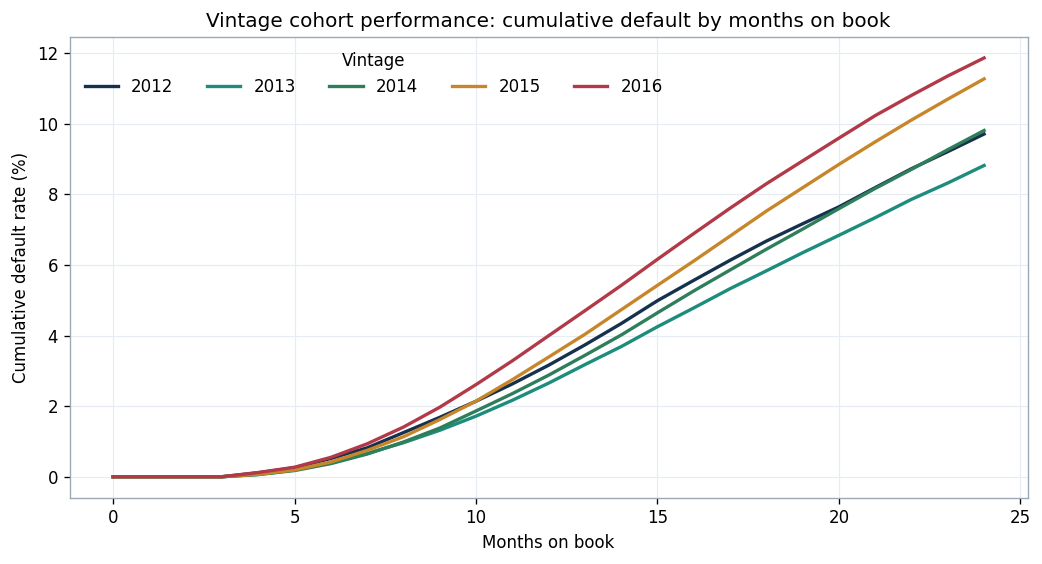

In [9]:
display(Image(filename="figures/01_vintage_curves.png"))

### 12-month default rate by vintage

In [10]:
# F2 12-month default by vintage
fig,ax=plt.subplots(figsize=(8.6,4.5))
ks=list(dr12.keys()); vs=[dr12[k] for k in ks]
bars=ax.bar([str(k)+("*" if k in partial else "") for k in ks],vs,color=NAVY,edgecolor="white")
for i,k in enumerate(ks):
    if k in partial: bars[i].set_color(GREY)   # only early issues of this vintage are observable
ax.plot([str(k)+("*" if k in partial else "") for k in ks],[dr12_adj[k] for k in ks],'o--',color=TEAL,lw=1.6,label="at 2013 grade mix")
ax.axhline(np.mean(vs[:3]),color=AMBER,ls='--',lw=1.4,label="early-vintage average")
for i,v in enumerate(vs): ax.text(i,v,f"{v:.1f}",ha="center",va="bottom",fontsize=8.5)
ax.set_ylabel("Default within 12 months of issue (%)")
ax.set_title("Early-warning: 12-month default rate by vintage" + (" (* partly observable)" if partial else ""))
ax.legend(frameon=False); plt.tight_layout(); plt.savefig(f"{FIG}/02_vintage_12mob.png",bbox_inches="tight"); plt.close()

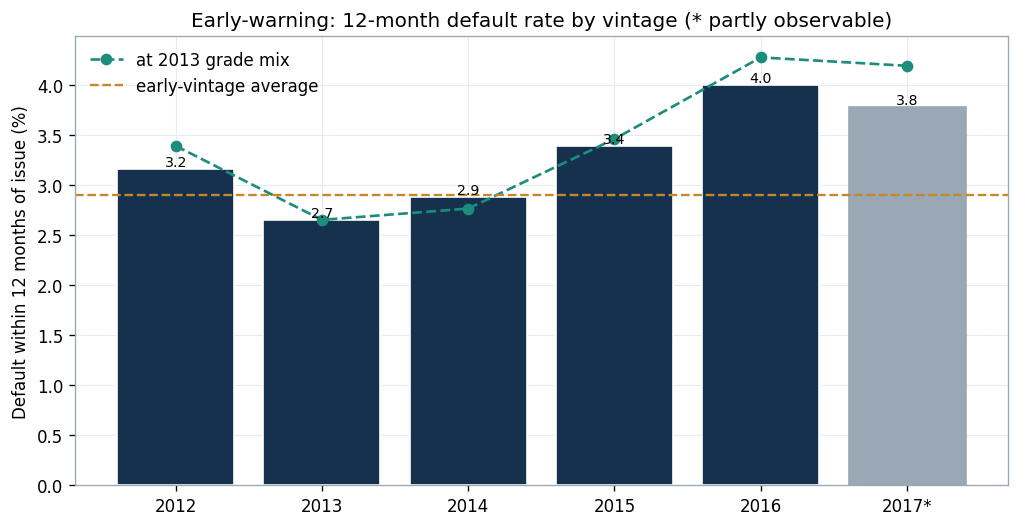

In [11]:
display(Image(filename="figures/02_vintage_12mob.png"))

### Live-book arrears profile

In [12]:
# F3 delinquency profile
fig,ax=plt.subplots(figsize=(8.6,4.5))
vals=[ead_by[b] for b in BUCKETS]; cols=[GREEN,"#8FB99B",AMBER,"#C8862B",RED]
ax.bar([lab[b] for b in BUCKETS],vals,color=cols,edgecolor="white")
ax.yaxis.set_major_formatter(FuncFormatter(usd))
ax.set_title(f"Live-book arrears profile (active EAD ${tot_ead/1e9:.1f}bn, 16+ dpd {delinq_rate:.1f}%)")
plt.tight_layout(); plt.savefig(f"{FIG}/03_delinquency_profile.png",bbox_inches="tight"); plt.close()

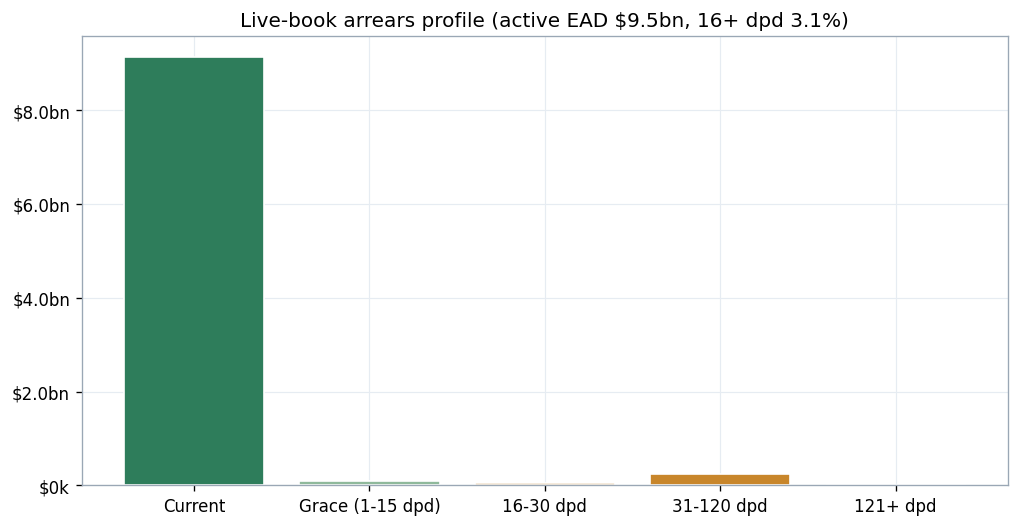

In [13]:
display(Image(filename="figures/03_delinquency_profile.png"))

### Application-score drift by vintage

In [14]:
# F4 PSI drift
fig,ax=plt.subplots(figsize=(8.6,4.5))
ks=list(psi_by.keys()); vs=[psi_by[k] for k in ks]
ax.plot([str(k) for k in ks],vs,'o-',color=NAVY,lw=2)
ax.axhline(0.10,color=AMBER,ls='--',lw=1.3,label="0.10 moderate shift")
ax.axhline(0.25,color=RED,ls='--',lw=1.3,label="0.25 significant shift")
ax.set_ylabel("PSI vs 2013-14 baseline"); ax.set_title("Application-score population drift by vintage (all issued loans)")
ax.set_ylim(0,max(0.3,max(vs)*1.2)); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(f"{FIG}/04_psi_drift.png",bbox_inches="tight"); plt.close()

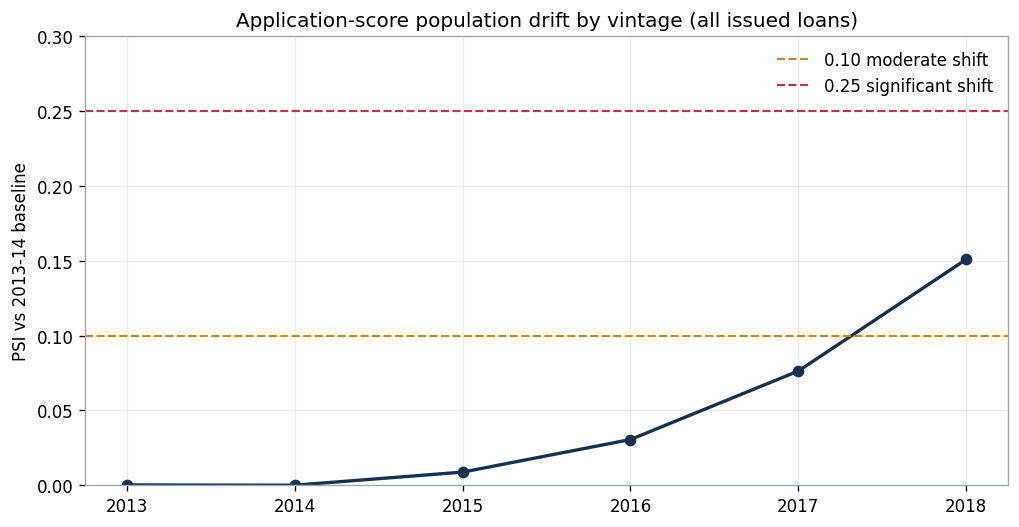

In [15]:
display(Image(filename="figures/04_psi_drift.png"))

### Geographic concentration

In [16]:
# F5 concentration by state
fig,ax=plt.subplots(figsize=(9,4.6)); top=st_share.head(10)*100
ax.bar(top.index,top.values,color=NAVY,edgecolor="white")
ax2=ax.twinx(); ax2.plot(range(len(top)),np.cumsum(top.values),'o-',color=AMBER,lw=2,label="cumulative")
ax.set_ylabel("Share of active EAD (%)"); ax2.set_ylabel("Cumulative (%)",color=AMBER)
ax.set_title(f"Geographic concentration: top-10 states (HHI {hhi_state:.3f}, well-diversified)")
plt.tight_layout(); plt.savefig(f"{FIG}/05_concentration_state.png",bbox_inches="tight"); plt.close()

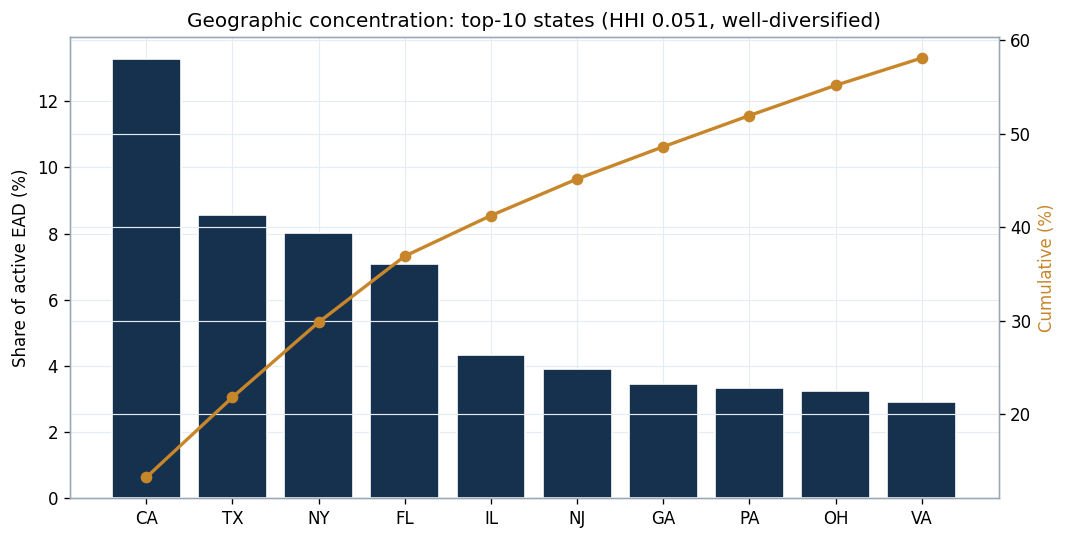

In [17]:
display(Image(filename="figures/05_concentration_state.png"))

### Early-warning dashboard

In [18]:
# F6 early-warning RAG dashboard
fig,ax=plt.subplots(figsize=(9.4,4.4)); ax.axis('off')
ax.set_xlim(0,10); ax.set_ylim(0,len(EWI)+1)
ax.text(0.1,len(EWI)+0.4,"Early-warning indicators",fontsize=13,fontweight='bold',color=NAVY)
for i,(name,val,r) in enumerate(EWI):
    y=len(EWI)-1-i
    ax.add_patch(Rectangle((0.1,y+0.1),9.8,0.8,facecolor="#F4F7FA",edgecolor="#E0E6EC"))
    ax.text(0.3,y+0.5,name,va='center',fontsize=10.5,color=NAVY)
    ax.text(6.3,y+0.5,val,va='center',fontsize=10,color=SLATE)
    ax.add_patch(Rectangle((9.25,y+0.25),0.5,0.5,facecolor=RAGC[r],edgecolor="white"))
plt.tight_layout(); plt.savefig(f"{FIG}/06_ewi_dashboard.png",bbox_inches="tight",dpi=130); plt.close()

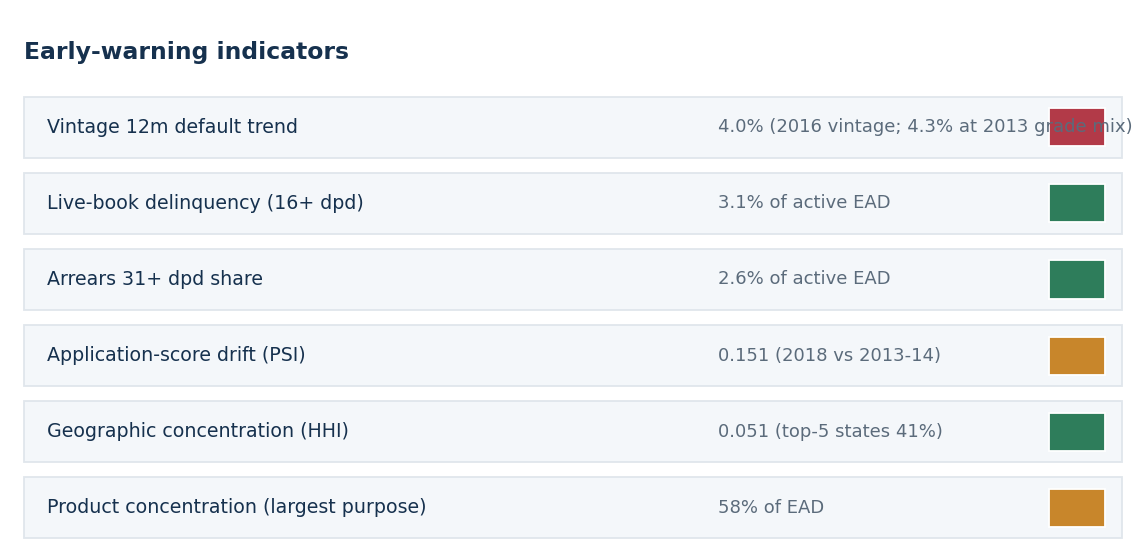

In [19]:
display(Image(filename="figures/06_ewi_dashboard.png"))

### Default rate by risk band: early vs recent vintages
Loans in the same PD band defaulted more often in the 2016-17 vintages than in 2013-14, which points to
worse outcomes at the same application risk rather than only a riskier mix.

In [20]:
# F7 score-band default: early vs recent vintages (quality drift)
pf['band']=pd.qcut(pf['pd'],8,duplicates='drop',labels=False)
obs=pf['obs_12']
early=pf[pf['issue_year'].isin([2013,2014])&obs].groupby('band')['bad_12'].mean()*100
recent=pf[pf['issue_year'].isin([2016,2017])&obs].groupby('band')['bad_12'].mean()*100
fig,ax=plt.subplots(figsize=(8.6,4.5)); x=np.arange(len(early)); w=0.4
ax.bar(x-w/2,early.values,w,label="2013-14 vintages",color=NAVY,edgecolor="white")
ax.bar(x+w/2,recent.reindex(early.index).values,w,label="2016-17 vintages",color=AMBER,edgecolor="white")
ax.set_xticks(x); ax.set_xticklabels([f"D{i+1}" for i in x],fontsize=8.5)
ax.set_xlabel("PD band (low to high risk)"); ax.set_ylabel("12-month default rate (%)")
ax.set_title("Default rate by risk band: early vs recent vintages"); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(f"{FIG}/07_band_trend.png",bbox_inches="tight"); plt.close()

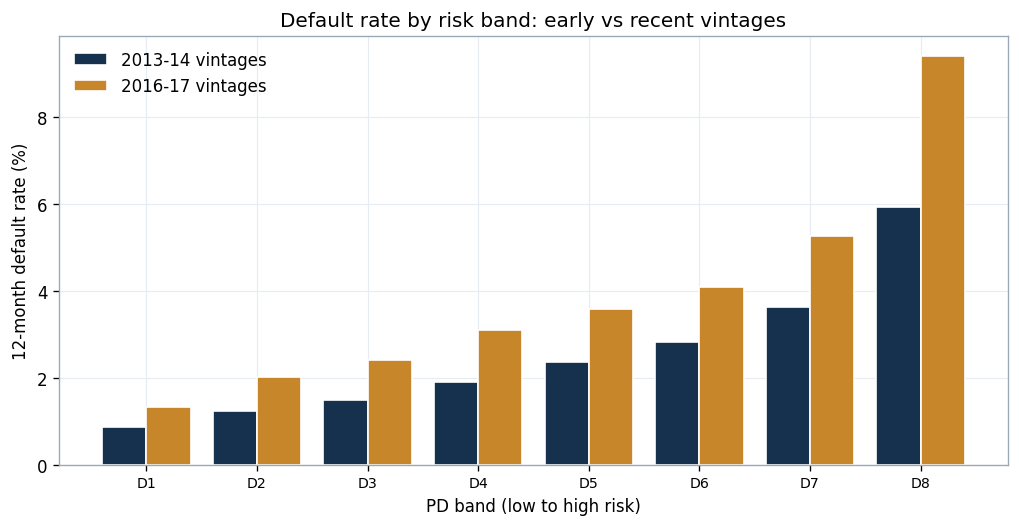

In [21]:
display(Image(filename="figures/07_band_trend.png"))

## Save the results
`results.json` holds every number quoted in the README and MI pack.

In [22]:
# =====================================================================
S=dict(
 n_loans=int(len(df)),ttc_default=round(float(ttc),4),
 active_loans=int(len(act)),active_ead=round(float(tot_ead),0),
 delinquency_rate_16dpd=round(delinq_rate,2),arrears_31dpd_share=round(arrears30_share,2),
 snapshot=lc.month_label(SNAP),dr12_definition="default dated within 12 months of issue; default = last payment + 4 months",
 dr12_observable_share={int(k):round(v,3) for k,v in dr12_obs_share.items()},
 dr12_at_2013_grade_mix={int(k):round(v,2) for k,v in dr12_adj.items()},psi_n_loans={int(k):v for k,v in psi_n.items()},
 dr12_by_vintage={int(k):round(v,2) for k,v in dr12.items()},
 psi_by_vintage={int(k):round(v,3) for k,v in psi_by.items()},
 hhi_state=round(hhi_state,3),top5_state_pct=round(top5_state,1),hhi_grade=round(hhi_grade,3),
 largest_purpose_pct=round(top_purpose,1),
 ewi=[{"indicator":n,"value":v,"rag":r} for n,v,r in EWI])
json.dump(S,open(f"{OUT}/results.json","w"),indent=2)
pd.DataFrame({'state':st.index,'active_ead':st.values,'share_pct':(st_share.values*100).round(2)}).to_csv(f"{DAT}/exposure_by_state.csv",index=False)
print("\n=== SUMMARY ==="); print(json.dumps(S,indent=2)); print("DONE")


=== SUMMARY ===
{
  "n_loans": 2260668,
  "ttc_default": 0.1192,
  "active_loans": 907904,
  "active_ead": 9510384856.0,
  "delinquency_rate_16dpd": 3.08,
  "arrears_31dpd_share": 2.57,
  "snapshot": "Mar 2019",
  "dr12_definition": "default dated within 12 months of issue; default = last payment + 4 months",
  "dr12_observable_share": {
    "2012": 1.0,
    "2013": 1.0,
    "2014": 1.0,
    "2015": 1.0,
    "2016": 1.0,
    "2017": 0.733
  },
  "dr12_at_2013_grade_mix": {
    "2012": 3.39,
    "2013": 2.65,
    "2014": 2.77,
    "2015": 3.46,
    "2016": 4.28,
    "2017": 4.19
  },
  "psi_n_loans": {
    "2013": 134814,
    "2014": 235629,
    "2015": 421095,
    "2016": 434407,
    "2017": 443579,
    "2018": 495241
  },
  "dr12_by_vintage": {
    "2012": 3.16,
    "2013": 2.65,
    "2014": 2.88,
    "2015": 3.39,
    "2016": 3.99,
    "2017": 3.78
  },
  "psi_by_vintage": {
    "2013": 0.0,
    "2014": 0.0,
    "2015": 0.009,
    "2016": 0.031,
    "2017": 0.076,
    "2018": 0.151


## Limitations
- **Approximate default dating.** Default is dated at last payment plus four months; the file has no
  delinquency history, so roll rates between arrears buckets cannot be measured.
- **A single snapshot.** Lending Club published one cut of the data, so this is one month's pack, not a
  time series of packs. Trends come from comparing vintages.
- **Late-2016 curves.** In the cumulative curves the last few months of the 2016 vintage are slightly
  understated for loans issued late in the year, which had not quite reached 24 months plus the
  charge-off allowance.
- **Illustrative limits.** The RAG thresholds are reasonable defaults, not a calibrated risk appetite.